# World of Goo - Nivel 1
## Fase 1: modelo combinatorio-geometrico (sin fisica)

Notebook de prueba minima para el **Taller 2**: verificar que se puede observar
el estado del ambiente y ejecutar acciones programaticamente.

**No** usa motor de fisica ni interfaz grafica. Solo geometria y teoria de grafos.

Ejecutar las celdas en orden con `Shift + Enter`.

---

### Que se modela y que no

| Elemento | Fase 1 (este notebook) | Fase 2 (con fisica) |
|---|---|---|
| Estructura como grafo | si | si |
| Planaridad (uniones no se cruzan) | si | si |
| Suelo | si, como restriccion geometrica | si, como colision |
| Rigidez | garantizada por Henneberg | idem |
| Tension en las uniones | **no** | si |
| Colapso | **no ocurre** | falla de resistencia |
| Deformacion bajo peso | **no** | si |

En Fase 1 la estructura es infinitamente rigida: se coloca una bola y queda
donde se puso. Esto es coherente porque la regla de construccion preserva la
rigidez, asi que el modelo geometrico no es una version mutilada del problema
sino un problema bien definido por si mismo.

---
## 1. Dependencias

In [13]:
# Primera vez:  uv add networkx matplotlib jupyter

import math
import itertools
import networkx as nx
import matplotlib.pyplot as plt

print("networkx  ", nx.__version__)
import matplotlib
print("matplotlib", matplotlib.__version__)

networkx   3.6.1
matplotlib 3.11.1


---
## 2. Parametros del modelo

Extraidos de `res/balls/common/balls.xml` del repositorio OpenGOO. Ese archivo
sigue el formato de assets originales de World of Goo (el repo incluye un
`Decrypter` AES para descifrarlos), asi que los valores son plausiblemente
los del juego real y no invenciones del clon.

```xml
shape="circle,30,0.25"   mass="30"   towermass="3.0"   strands="2"
<strand type="spring" minlen="100" maxlen1="200" maxforce="1000"/>
```

`maxlen1 = 200` define el **alcance maximo que puede aportar una bola**, o sea
el denominador de la heuristica de A*.

`strands="2"` confirma que cada bola se ancla a exactamente 2 existentes.
El codigo del clon lo verifica: si hay menos de 2 candidatas, no engancha nada.

In [14]:
R_BOLA   = 15.0     # diametro 30 -> radio 15
MINLEN   = 100.0    # largo minimo de una union
MAXLEN   = 200.0    # largo maximo = alcance maximo por bola
L_REPOSO = (MINLEN + MAXLEN) / 2      # 150 px

BOLAS_DISPONIBLES = 14
META_Y  = 600.0     # altura de la caneria    (A MEDIR del juego real)
Y_SUELO = 0.0       # altura del terreno      (A MEDIR del juego real)

print(f"largo de reposo: {L_REPOSO:.0f} px")
print(f"una bola no puede quedar por debajo de y = {Y_SUELO + R_BOLA:.0f} px")

largo de reposo: 150 px
una bola no puede quedar por debajo de y = 15 px


---
## 3. Geometria

### La decision de discretizacion

Hay una inversion respecto al juego real que conviene tener explicita:

- **En el juego:** el jugador elige una *posicion*, y el motor decide a que
  bolas se engancha (las que esten dentro de `minlen`-`maxlen`).
- **En este modelo:** el agente elige las *conexiones*, y la geometria
  determina la posicion.

Se eligio la segunda porque garantiza exactamente 2 anclajes, hace la
planaridad verificable y produce un espacio de acciones discreto.

Pero dado un par `(i, j)`, la bola nueva no queda en un unico punto: puede ir
en cualquier lugar de la **interseccion de dos coronas circulares** (radio
`MINLEN` a `MAXLEN` alrededor de cada ancla). Es una region 2D, no un punto.

Por eso la accion se parametriza como `(i, j, L_i, L_j, lado)`, discretizando
cada largo en `k` valores dentro de `[MINLEN, MAXLEN]`. El caso isosceles
(`L_i = L_j = 150`) es simplemente `k = 1`.

In [15]:
def dist(p, q):
    return math.dist(p, q)


def interseccion(A, B, La, Lb, lado):
    """
    Punto P tal que |P-A| = La y |P-B| = Lb.
    'lado' (+1/-1) elige cual de las dos soluciones (una a cada lado de A-B).
    Devuelve None si los circulos no se cortan.
    """
    d = dist(A, B)
    if d == 0 or d > La + Lb or d < abs(La - Lb):
        return None
    a = (La**2 - Lb**2 + d**2) / (2 * d)      # proyeccion sobre A-B
    r = La**2 - a**2
    if r < 0:
        return None
    h = math.sqrt(r)                           # distancia perpendicular
    ux, uy = (B[0] - A[0]) / d, (B[1] - A[1]) / d
    bx, by = A[0] + a * ux, A[1] + a * uy      # pie de la perpendicular
    return (bx - uy * h * lado, by + ux * h * lado)


def se_cruzan(p1, p2, p3, p4):
    """Interseccion propia entre segmentos p1-p2 y p3-p4."""
    def orient(a, b, c):
        v = (b[0]-a[0])*(c[1]-a[1]) - (b[1]-a[1])*(c[0]-a[0])
        return 0 if abs(v) < 1e-9 else (1 if v > 0 else -1)
    if p1 in (p3, p4) or p2 in (p3, p4):
        return False                                  # comparten extremo
    return (orient(p1,p2,p3) != orient(p1,p2,p4) and
            orient(p3,p4,p1) != orient(p3,p4,p2))


def largos(k):
    """k valores de largo de union, equiespaciados en [MINLEN, MAXLEN]."""
    if k <= 1:
        return [L_REPOSO]
    paso = (MAXLEN - MINLEN) / (k - 1)
    return [MINLEN + i * paso for i in range(k)]


A, B = (0.0, 0.0), (150.0, 0.0)
print("isosceles  (150,150) lado +1:", interseccion(A, B, 150, 150, +1))
print("asimetrico (100,200) lado +1:", interseccion(A, B, 100, 200, +1))
print()
print("largos(1):", [f"{x:.0f}" for x in largos(1)])
print("largos(3):", [f"{x:.0f}" for x in largos(3)])
print("largos(5):", [f"{x:.0f}" for x in largos(5)])

isosceles  (150,150) lado +1: (75.0, 129.9038105676658)
asimetrico (100,200) lado +1: (-25.0, 96.82458365518542)

largos(1): ['150']
largos(3): ['100', '150', '200']
largos(5): ['100', '125', '150', '175', '200']


### Planaridad abstracta vs. geometrica

`networkx.check_planarity` responde si el grafo **puede** dibujarse sin cruces,
no si el dibujo actual los tiene. Son cosas distintas y hacen falta las dos:

- La geometrica (`se_cruzan`) es la que valida cada accion.
- La abstracta sirve de verificacion global y devuelve el *embedding*.

In [16]:
print("K4 planar:", nx.check_planarity(nx.complete_graph(4))[0])
print("K5 planar:", nx.check_planarity(nx.complete_graph(5))[0])

K4 planar: True
K5 planar: False


---
## 4. El estado

Un estado es: **grafo + posiciones + bolas restantes**.

La accion es una *extension de Henneberg tipo I* (agregar un vertice de grado 2).
Por el teorema de Laman, una estructura de barras en 2D es minimamente rigida
cuando `E = 2V - 3`. Henneberg I suma 1 vertice y 2 aristas, asi que ambos lados
crecen en 2 y **el balance se conserva**: si la base es rigida, todo lo que se
construya encima tambien lo es.

In [17]:
class Estado:
    def __init__(self, G, pos, restantes):
        self.G, self.pos, self.restantes = G, pos, restantes

    @staticmethod
    def inicial(restantes=BOLAS_DISPONIBLES, base="K4"):
        """base="K4" -> juego original | base="triangulo" -> nivel de prueba del clon"""
        lado = L_REPOSO
        if base == "K4":
            pos = {0:(0.,0.), 1:(lado,0.), 2:(lado,lado), 3:(0.,lado)}
            G = nx.complete_graph(4)
        else:
            h = lado * math.sqrt(3) / 2
            pos = {0:(0.,0.), 1:(lado,0.), 2:(lado/2, h)}
            G = nx.complete_graph(3)
        return Estado(G, pos, restantes)

    def altura_max(self):
        return max(p[1] for p in self.pos.values())

    def laman(self):
        V, E = self.G.number_of_nodes(), self.G.number_of_edges()
        return V, E, 2*V - 3, E - (2*V - 3)

    def es_planar(self):
        return nx.check_planarity(self.G)[0]

    def heuristica(self):
        """h(n) en unidades de BOLAS. Admisible: nunca sobreestima."""
        return max(0.0, (META_Y - self.altura_max()) / MAXLEN)

    def aplicar(self, accion):
        i, j, Li, Lj, lado, P = accion
        n = max(self.G.nodes) + 1
        G = self.G.copy(); G.add_node(n); G.add_edge(n,i); G.add_edge(n,j)
        pos = dict(self.pos); pos[n] = P
        return Estado(G, pos, self.restantes - 1)

    def resumen(self):
        V, E, lam, exc = self.laman()
        return (f"V={V}  E={E}  2V-3={lam}  exceso={exc}  "
                f"altura={self.altura_max():6.1f}  restantes={self.restantes}  "
                f"h(n)={self.heuristica():.2f}")

e = Estado.inicial()
print(e.resumen())

V=4  E=6  2V-3=5  exceso=1  altura= 150.0  restantes=14  h(n)=2.25


---
## 5. Visualizacion

Solo para entender lo que pasa. El entorno de entrenamiento corre sin esto.

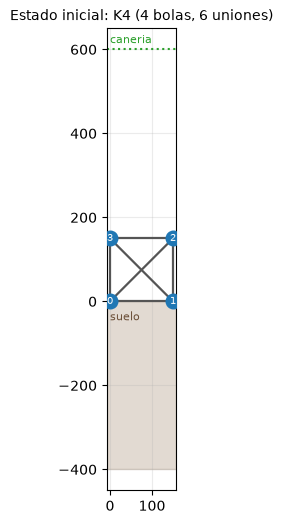

In [18]:
def dibujar(e, titulo="", ax=None, candidatos=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(5.5, 6))
    for u, v in e.G.edges:                       # uniones
        ax.plot([e.pos[u][0], e.pos[v][0]],
                [e.pos[u][1], e.pos[v][1]],
                "-", lw=1.6, color="#555555", zorder=2)
    xs = [p[0] for p in e.pos.values()]
    ys = [p[1] for p in e.pos.values()]
    ax.scatter(xs, ys, s=110, color="#1f77b4", zorder=4)
    for n, p in e.pos.items():
        ax.annotate(str(n), p, color="white", ha="center", va="center",
                    fontsize=7, zorder=5)
    if candidatos:                               # posiciones alcanzables
        ax.scatter([a[5][0] for a in candidatos],
                   [a[5][1] for a in candidatos],
                   s=55, facecolors="none", edgecolors="#d62728",
                   linewidths=0.9, zorder=3,
                   label=f"{len(candidatos)} acciones validas")
        ax.legend(loc="upper left", fontsize=8)
    ax.axhline(META_Y, color="#2ca02c", ls=":", lw=1.5)
    ax.annotate("caneria", (min(xs), META_Y + 15), color="#2ca02c", fontsize=8)
    ax.axhspan(Y_SUELO - 400, Y_SUELO, color="#8c6d4f", alpha=0.25, zorder=0)
    ax.annotate("suelo", (min(xs), Y_SUELO - 45), color="#6b4f38", fontsize=8)
    ax.set_aspect("equal"); ax.set_title(titulo, fontsize=10)
    ax.grid(alpha=0.25)
    return ax

dibujar(e, "Estado inicial: K4 (4 bolas, 6 uniones)")
plt.show()

---
## 6. Generacion de acciones

Cuatro filtros, ordenados de mas barato a mas caro:

1. **Suelo** - la bola no puede quedar enterrada.
2. **Alcance** - las dos uniones deben medir entre `MINLEN` y `MAXLEN`.
3. **Solapamiento** - la bola nueva no puede pisar una existente.
4. **Cruce** - las uniones nuevas no pueden cruzar uniones existentes.

Los tres primeros son restricciones fisicas del juego; el cuarto es la
**planaridad**, que el motor de fisica no impone por si solo (en el clon las
bolas ni siquiera colisionan entre si) y hay que declarar explicitamente como
condicion de validez.

No se generan acciones nulas: toda accion valida modifica la estructura.

Se deduplican posiciones muy cercanas entre si, ya que distintos pares
`(L_i, L_j)` pueden dar practicamente el mismo punto.

In [19]:
def acciones(e, k=1, verbose=False, tol=2.0):
    if e.restantes == 0:
        return []
    validas, vistos = [], set()
    desc = {"suelo": 0, "alcance": 0, "solapa": 0, "cruce": 0, "duplicado": 0}
    LS = largos(k)

    for (i, j) in itertools.combinations(e.G.nodes, 2):
        for Li, Lj, lado in itertools.product(LS, LS, (+1, -1)):
            P = interseccion(e.pos[i], e.pos[j], Li, Lj, lado)
            if P is None:
                desc["alcance"] += 1; continue

            # 1. suelo
            if P[1] < Y_SUELO + R_BOLA:
                desc["suelo"] += 1; continue

            # 2. alcance (garantizado por construccion; queda como guarda)
            if not (MINLEN <= dist(P, e.pos[i]) <= MAXLEN and
                    MINLEN <= dist(P, e.pos[j]) <= MAXLEN):
                desc["alcance"] += 1; continue

            # 3. solapamiento con bolas existentes
            if any(dist(P, q) < 2 * R_BOLA for q in e.pos.values()):
                desc["solapa"] += 1; continue

            # 4. cruce de uniones (planaridad geometrica)
            nuevas = [(P, e.pos[i]), (P, e.pos[j])]
            if any(se_cruzan(a, b, e.pos[u], e.pos[v])
                   for a, b in nuevas for u, v in e.G.edges):
                desc["cruce"] += 1; continue

            clave = (i, j, round(P[0]/tol), round(P[1]/tol))
            if clave in vistos:
                desc["duplicado"] += 1; continue
            vistos.add(clave)

            validas.append((i, j, Li, Lj, lado, P))

    if verbose:
        bruto = len(validas) + sum(desc.values())
        print(f"k = {k}   ->   largos posibles: {[f'{x:.0f}' for x in LS]}")
        print(f"candidatos brutos            : {bruto}")
        print(f"  descartados por suelo      : {desc['suelo']}")
        print(f"  descartados por alcance    : {desc['alcance']}")
        print(f"  descartados por solapar    : {desc['solapa']}")
        print(f"  descartados por cruce      : {desc['cruce']}")
        print(f"  duplicados                 : {desc['duplicado']}")
        print(f"ACCIONES VALIDAS             : {len(validas)}")
    return validas


acc = acciones(e, k=1, verbose=True)
print()
for n, (i, j, Li, Lj, lado, P) in enumerate(acc):
    print(f"  accion {n}: ({i},{j}) L=({Li:.0f},{Lj:.0f}) lado {lado:+d} "
          f"-> ({P[0]:7.1f}, {P[1]:7.1f})")

k = 1   ->   largos posibles: ['150']
candidatos brutos            : 12
  descartados por suelo      : 3
  descartados por alcance    : 0
  descartados por solapar    : 2
  descartados por cruce      : 4
  duplicados                 : 0
ACCIONES VALIDAS             : 3

  accion 0: (0,3) L=(150,150) lado +1 -> ( -129.9,    75.0)
  accion 1: (1,2) L=(150,150) lado -1 -> (  279.9,    75.0)
  accion 2: (2,3) L=(150,150) lado -1 -> (   75.0,   279.9)


Con `k = 1` (isosceles, el caso mas restringido) quedan pocas acciones, y las
que apuntaban hacia abajo ahora se descartan por el suelo. Comparar con `k = 3`:

In [20]:
acc3 = acciones(e, k=3, verbose=True)

k = 3   ->   largos posibles: ['100', '150', '200']
candidatos brutos            : 108
  descartados por suelo      : 28
  descartados por alcance    : 10
  descartados por solapar    : 8
  descartados por cruce      : 31
  duplicados                 : 0
ACCIONES VALIDAS             : 31


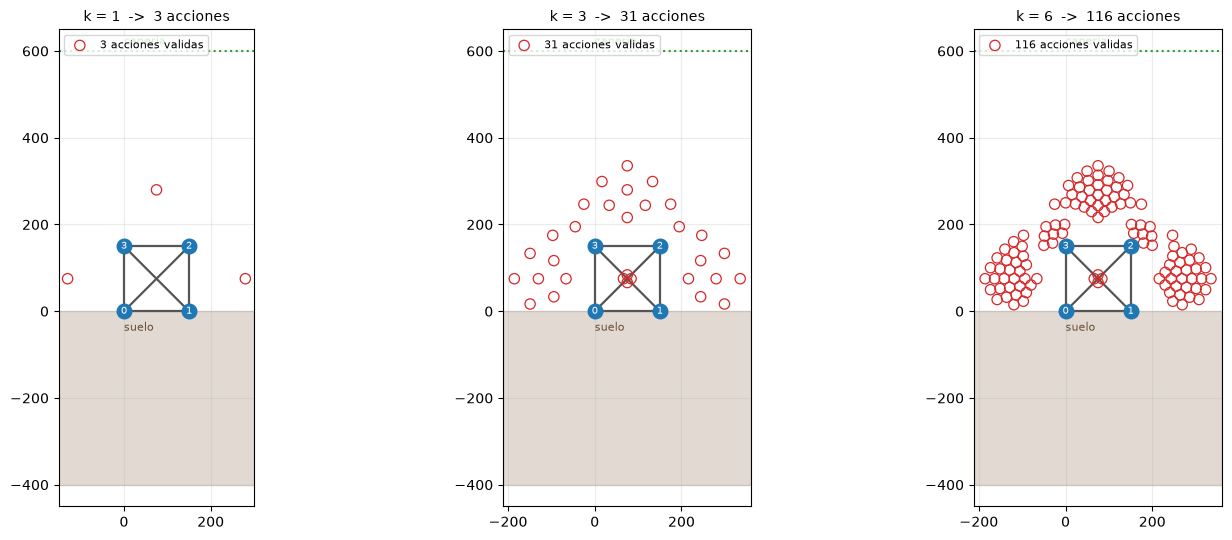

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5.5))
for ax, k in zip(axes, [1, 3, 6]):
    a = acciones(e, k=k)
    dibujar(e, f"k = {k}  ->  {len(a)} acciones", ax=ax, candidatos=a)
plt.tight_layout(); plt.show()

Se ve la **region alcanzable** tomando forma. Cada par de anclaje genera una
lente (interseccion de dos coronas circulares) y `k` controla con que
resolucion se la muestrea. El caso isosceles era solo el centro de cada lente.

---
## 7. El parametro k: resolucion contra tamano del espacio

`k` es la perilla que decide cuanto del espacio real se cubre y cuanto cuesta
explorarlo. Esto responde directamente a la acotacion del profesor sobre
**definir que aristas se permite expandir, con heuristicas**: la heuristica no
solo guia la busqueda, tambien decide que candidatos se generan.

In [22]:
print(f"{'k':<5}{'acciones en K4':<18}{'tras 4 bolas mas':<20}{'crecimiento'}")
print("-" * 58)

for k in [1, 2, 3, 4, 6, 8]:
    e0 = Estado.inicial()
    n0 = len(acciones(e0, k=k))
    st = e0
    for _ in range(4):                      # greedy de altura, 4 pasos
        a = acciones(st, k=k)
        if not a:
            break
        st = st.aplicar(max(a, key=lambda x: x[5][1]))
    n1 = len(acciones(st, k=k))
    print(f"{k:<5}{n0:<18}{n1:<20}{n1/max(n0,1):.1f}x")

k    acciones en K4    tras 4 bolas mas    crecimiento
----------------------------------------------------------
1    3                 9                   3.0x
2    16                22                  1.4x
3    31                66                  2.1x
4    54                133                 2.5x
6    116               294                 2.5x
8    179               505                 2.8x


La lectura: con `k` chico el espacio es enumerable por fuerza bruta y sirve
para calcular el **optimo exacto** de referencia. Con `k` grande la
representacion es mas fiel al juego pero la ramificacion obliga a usar A* o
metaheuristicas.

Es un compromiso explicito y parametrizado, no una simplificacion escondida.

---
## 8. Aplicar una accion

Elegimos la que mas altura gana y observamos el estado resultante.
Mirar que **el exceso de Laman no cambia**.

antes  : V=4  E=6  2V-3=5  exceso=1  altura= 150.0  restantes=14  h(n)=2.25

accion : anclar en (2,3) con L=(200,200) lado -1

despues: V=5  E=8  2V-3=7  exceso=1  altura= 335.4  restantes=13  h(n)=1.32

+1 nodo y +2 aristas = extension de Henneberg tipo I.
El exceso de Laman se conserva: la rigidez se preserva.


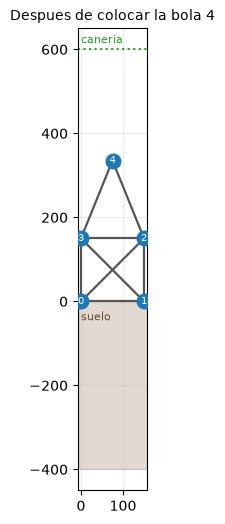

In [23]:
print("antes  :", e.resumen())

elegida = max(acciones(e, k=3), key=lambda a: a[5][1])
i, j, Li, Lj, lado, P = elegida
print(f"\naccion : anclar en ({i},{j}) con L=({Li:.0f},{Lj:.0f}) lado {lado:+d}\n")

e2 = e.aplicar(elegida)
print("despues:", e2.resumen())
print("\n+1 nodo y +2 aristas = extension de Henneberg tipo I.")
print("El exceso de Laman se conserva: la rigidez se preserva.")

dibujar(e2, "Despues de colocar la bola 4")
plt.show()

---
## 9. Construccion greedy

Repetimos eligiendo siempre la accion que mas sube. Es el comportamiento que
tendria A* guiado **solo** por la heuristica de altura, sin corregirla.

In [24]:
K = 3
e = Estado.inicial()
historia = [e]
filas = []

for paso in range(1, 9):
    accs = acciones(e, k=K)
    if not accs:
        print("sin acciones validas"); break
    ramif = len(accs)
    mejor = max(accs, key=lambda a: a[5][1])
    e = e.aplicar(mejor)
    historia.append(e)
    V, E, lam, exc = e.laman()
    filas.append((paso, mejor[0], mejor[1], ramif, V, E, lam, exc,
                  e.altura_max(), e.heuristica()))

print(f"{'paso':<6}{'anclaje':<11}{'ramif':<8}{'V':<4}{'E':<4}"
      f"{'2V-3':<6}{'exc':<5}{'altura':<10}{'h(n)'}")
print("-" * 62)
for f in filas:
    print(f"{f[0]:<6}({f[1]:>2},{f[2]:>2})    {f[3]:<8}"
          f"{f[4]:<4}{f[5]:<4}{f[6]:<6}{f[7]:<5}{f[8]:<10.1f}{f[9]:.2f}")

paso  anclaje    ramif   V   E   2V-3  exc  altura    h(n)
--------------------------------------------------------------
1     ( 2, 3)    31      5   8   7     1    335.4     1.32
2     ( 2, 4)    36      6   10  9     1    335.4     1.32
3     ( 4, 5)    50      7   12  11    1    520.8     0.40
4     ( 4, 6)    57      8   14  13    1    533.9     0.33
5     ( 6, 7)    66      9   16  15    1    719.3     0.00
6     ( 7, 8)    78      10  18  17    1    732.5     0.00
7     ( 8, 9)    82      11  20  19    1    866.1     0.00
8     ( 9,10)    88      12  22  21    1    879.2     0.00


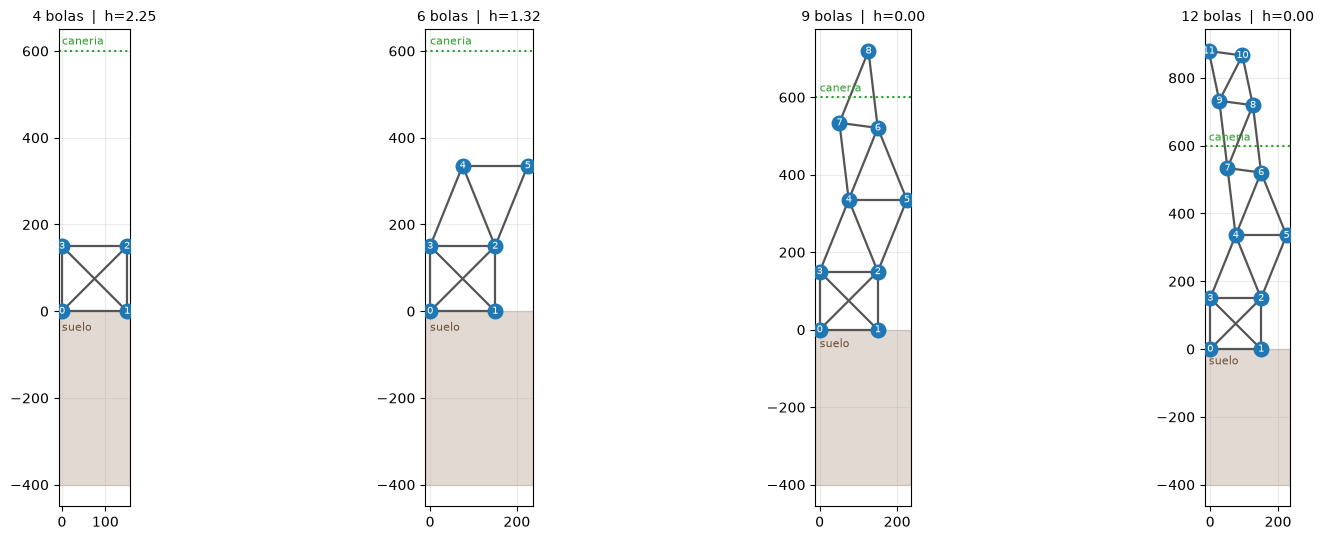

In [25]:
fig, axes = plt.subplots(1, 4, figsize=(17, 5.5))
for ax, idx in zip(axes, [0, 2, 5, 8]):
    st = historia[min(idx, len(historia)-1)]
    dibujar(st, f"{st.G.number_of_nodes()} bolas  |  h={st.heuristica():.2f}", ax=ax)
plt.tight_layout(); plt.show()

---
## 10. Lectura de los resultados

**La ramificacion crece con la profundidad.** Cada bola nueva habilita mas
pares de anclaje, asi que el arbol de busqueda se *ensancha* en vez de
angostarse. Es lo contrario de lo habitual y explica por que con presupuesto
chico se puede enumerar y con presupuesto grande no.

**El exceso de Laman se mantiene constante.** La estructura es siempre rigida
por construccion. Por lo tanto, cuando se agregue fisica (Fase 2), el colapso
sera **falla de resistencia** (la tension supera `maxforce`), nunca falla de
rigidez.

**La heuristica es admisible.** `h(n)` supone que cada bola gana `MAXLEN` de
altura, cosa que ninguna secuencia real logra sostener. Al subestimar el costo
real, cumple la condicion que A* necesita para garantizar optimalidad.

**La heuristica es enganosa.** El greedy construye una torre fina y vertical,
justo el tipo de estructura mas propensa a colapsar. La senal que guia hacia
la meta esta en conflicto con la factibilidad estructural, y por eso hay que
penalizar configuraciones cuyo centro de masa se aleje de la base de apoyo.

---
## 11. El modelo no esta cableado a una base

El nivel 1 del juego original arranca con 4 bolas conectadas entre si (K4).
El `level1` del clon OpenGOO arranca con un triangulo, asi que **no** es el
nivel real: el repo sirve para parametros fisicos, no para geometria.

| Base | V | E | 2V-3 | Exceso |
|---|---|---|---|---|
| Triangulo | 3 | 3 | 3 | 0 (minimamente rigido) |
| K4 | 4 | 6 | 5 | 1 (una union redundante) |

En ambos casos Henneberg preserva la rigidez, asi que la conclusion sobre el
modo de falla no depende de cual sea la base.

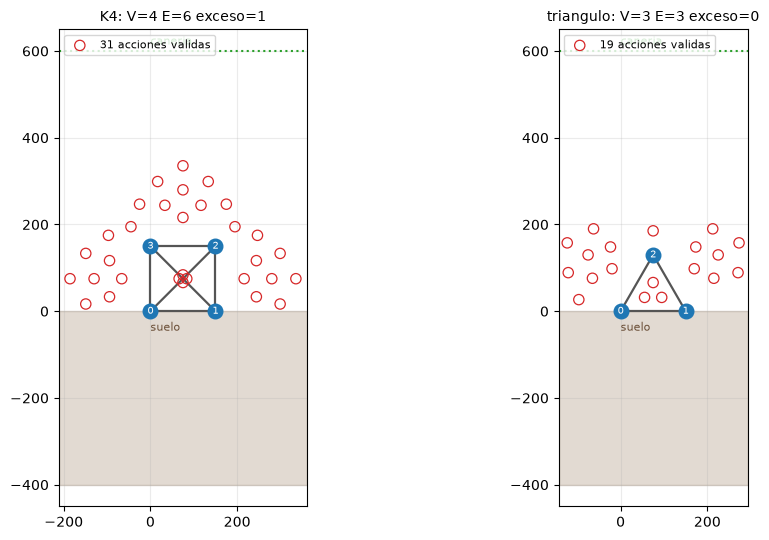

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
for ax, base in zip(axes, ["K4", "triangulo"]):
    st = Estado.inicial(base=base)
    V, E, lam, exc = st.laman()
    dibujar(st, f"{base}: V={V} E={E} exceso={exc}", ax=ax,
            candidatos=acciones(st, k=3))
plt.tight_layout(); plt.show()

---
## 12. Conclusion para el Taller 2

Queda verificado que con **NetworkX** se puede:

- representar el estado del ambiente (grafo + geometria + presupuesto),
- generar el conjunto de acciones validas, filtrando por suelo, alcance,
  solapamiento y planaridad,
- ejecutar una accion y observar el estado resultante,
- calcular la heuristica de A* en unidades de bolas,
- controlar la resolucion del espacio de acciones con el parametro `k`.

Todo sin motor de fisica ni interfaz grafica, y en milisegundos por paso.

### Pendiente de medir del juego real

| Parametro | Valor provisorio | Como obtenerlo |
|---|---|---|
| `META_Y` | 600 px | captura de pantalla, escalando con el diametro de bola (30 px) |
| `Y_SUELO` | 0 px | idem; el terreno real no es plano |
| geometria inicial | cuadrado de lado 150 | idem |

### Pendiente de decidir

- Valor de `k` para los experimentos, y si conviene fijo o adaptativo.
- Heuristica de calidad para ordenar candidatos (no solo validez): preferir
  los que ganan altura, triangulan sobre el borde, o mantienen el centro de
  masa sobre la base de apoyo.